In [1]:
!pip install matplotlib datasets torch transformers evaluate

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.0/469.0 KB 10.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 76.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.4/81.4 KB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 KB 12.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.0/213.0 KB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.5/110.5 KB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 KB 10.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 83.5 MB/s eta 0:00:00


In [2]:
import os
import random
import pandas as pd
from datasets import Dataset, Features, Value, ClassLabel
import collections
from collections import Counter
import matplotlib.pyplot as plt
from pathlib import Path
from datasets import DatasetDict
import evaluate
import torch
import numpy as np
from transformers import AdamW, AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#training set
training_set = [os.path.join("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set", f) for f in os.listdir("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set")]

#test_set 
test_set = [os.path.join("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set", f) for f in os.listdir("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set")]

#clarence dataset

#training set
#training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts")]

#test_set 
#test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts")]

training_set = random.sample(training_set, len(training_set))
test_set = random.sample(test_set, len(test_set))

print("Total: " + str(len(training_set) + len(test_set)))
print("Training Set: " + str(len(training_set)))
print("Test Set: " + str(len(test_set)))

Total: 4165
Training Set: 2915
Test Set: 1250


In [5]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass training and test set
training_set_labels, file_list, combined_training = make_labels(training_set)
test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

#dataframe with label and files, not text yet.
df_train = pd.DataFrame(data={ 'label':training_set_labels,'files': training_set})
df_test = pd.DataFrame(data={ 'label':test_set_labels,'files': test_set})
df_train

{'non-relevant': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/26119541_background.txt', 'non-clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/19954329_non-clinical.txt', 'clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/24359054_clinical.txt'}
{'non-clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/29358953_non-clinical.txt', 'non-relevant': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/30703333_background.txt', 'clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/23929313_clinical.txt'}


,label,files
0,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
1,non-clinical,/content/drive/MyDrive/Colab Notebooks/classif...
2,non-clinical,/content/drive/MyDrive/Colab Notebooks/classif...
3,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
4,clinical,/content/drive/MyDrive/Colab Notebooks/classif...
...,...,...
2910,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
2911,clinical,/content/drive/MyDrive/Colab Notebooks/classif...
2912,non-clinical,/content/drive/MyDrive/Colab Notebooks/classif...
2913,non-clinical,/content/drive/MyDrive/Colab Notebooks/classif...


Counter({'non-relevant': 1232, 'non-clinical': 844, 'clinical': 839})
OrderedDict([('clinical', 839), ('non-clinical', 844), ('non-relevant', 1232)])
[839, 844, 1232]


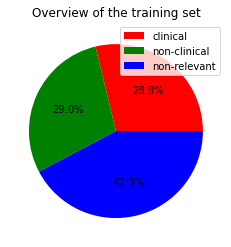

In [6]:
# to represent the distribution of the training set in a circular diagram

labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(training_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the training set')
plt.show()

Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
OrderedDict([('clinical', 248), ('non-clinical', 361), ('non-relevant', 641)])
[248, 361, 641]


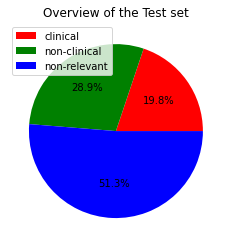

In [7]:
# to represent the distribution of the test:


labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [8]:
#load text of files 
X_train_text = [Path(file).read_text() for file in training_set]
X_test_text = [Path(file).read_text() for file in test_set]

In [9]:
df_train['text'] = X_train_text
df_test['text'] = X_test_text
df_train=df_train[["label", "text"]]
df_test=df_test[["label", "text"]]
df_train

,label,text
0,non-relevant,Interleukin-4 induced interferon regulatory fa...
1,non-clinical,Nano-ceramic composite scaffolds for bioreacto...
2,non-clinical,Enhanced differentiation of human embryonic st...
3,non-relevant,Toxicity evaluation of herbal pharmaceutical w...
4,clinical,"Antidepressant class, age, and the risk of del..."
...,...,...
2910,non-relevant,Epidemiology of elephantiasis with special emp...
2911,clinical,Feasibility and outcomes of hypofractionated s...
2912,non-clinical,Fibrin glues in combination with mesenchymal s...
2913,non-clinical,Evacuated calcium phosphate spherical microcar...


In [10]:
#dataset_train = Dataset.from_pandas(df_train)
#dataset_test = Dataset.from_pandas(df_test)

debbie_class_names = ["clinical", "non-clinical","non-relevant"]
debbie_features = Features({'text': Value('string'), 'label': ClassLabel(names=debbie_class_names)})
dataset_train = Dataset.from_pandas(df_train, features=debbie_features)
dataset_test = Dataset.from_pandas(df_test, features=debbie_features)
dataset_train

Dataset({
    features: ['text', 'label'],
    num_rows: 2915
})

In [11]:
raw_dataset = DatasetDict({"train":dataset_train,"validation":dataset_test})
raw_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1250
    })
})

In [12]:
raw_train_dataset = raw_dataset["train"]
raw_train_dataset[0]

{'text': 'Interleukin-4 induced interferon regulatory factor (Irf) 4 participates in the regulation of alternative macrophage priming.\nInterleukin (IL)-4 is a central regulator of T helper 2 (Th2) immune responses, and also has a major impact on innate immune cells. This cytokine primes macrophages for immune responses to parasites and induces a distinct macrophage phenotype that may also promote tissue repair. IL-4 signaling in macrophages is primarily mediated by the transcription factor signal transducer and activator of transcription 6 (Stat6), which in turn regulates a number of secondary DNA binding proteins that may participate in shaping the resulting phenotype. The impact of secondary transcription factors on IL-4-treated macrophages, however, is largely unknown. Here we show that interferon regulatory factor 4 (Irf4) is strongly induced on RNA and protein level in bone marrow-derived macrophages upon priming with IL-4. Using microarray-based whole genome expression analysis,

In [13]:
raw_train_dataset.features

{'text': Value(dtype='string', id=None),
 'label': ClassLabel(names=['clinical', 'non-clinical', 'non-relevant'], id=None)}

In [14]:
def compute_metrics(eval_pred):
    metric1 = evaluate.load("precision")
    metric2 = evaluate.load("recall")
    metric3 = evaluate.load("accuracy")
    metric4 = evaluate.load("f1")
    #metric5 = evaluate.load("BucketHeadP65/confusion_matrix")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision = metric1.compute(predictions=predictions, references=labels, average = 'macro')["precision"]
    recall = metric2.compute(predictions=predictions, references=labels, average = 'macro')["recall"]
    accuracy = metric3.compute(predictions=predictions, references=labels)["accuracy"]
    f1 = metric4.compute(predictions=predictions, references=labels, average = 'macro')["f1"]
    #confusion_matrix = metric5.compute(predictions=predictions, references=labels)["confusion_matrix"]
    return {"precision": precision, "recall": recall, "accuracy": accuracy, "f1": f1}

In [15]:

# Same as before
#checkpoint = "bert-base-uncased"
checkpoint = "dmis-lab/biobert-v1.1"

#model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

#esta parte de aqui no termina utilizandose solamnete el tokenizer


In [16]:
#revisar esta parte
from transformers import AutoConfig, AutoModelForSequenceClassification
# define the mappings as dictionaries
label2id = {'clinical':0, 'non-clinical':1, 'non-relevant': 2}
id2label = {0:'clinical', 1:'non-clinical', 2:'non-relevant'}
# define config
config = AutoConfig.from_pretrained(checkpoint, label2id=label2id, id2label=id2label, model_max_length=512)
# load model with config
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=config)
# export model
#model.save_pretrained(target_name_or_path)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dmis-lab/biobert-v1.1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [17]:
def tokenize_function(example):
    return tokenizer(example["text"], truncation=True) #cuidado agregue padding para usar la segunda opcion

In [18]:
tokenized_datasets = raw_dataset.map(tokenize_function, batched=True)
tokenized_datasets

Map:   0%|          | 0/2915 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1250
    })
})

In [19]:
#tokenized_datasets['train'][0]

In [20]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# BioBert Epoch = 3

In [21]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch")
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

In [22]:
trainer.train()

The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 3
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 1095
  Number of trainable parameters = 108312579
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method 

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.357939,0.858586,0.893785,0.877600,0.869648
2,0.305400,0.391114,0.874349,0.892976,0.896800,0.882580
3,0.152200,0.375180,0.891541,0.918385,0.910400,0.902079


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8


Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-1000
Configuration saved in debbie-trainer/checkpoint-1000/config.json
Model weights saved in debbie-trainer/checkpoint-1000/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-1000/tokenizer_config.json
Special tokens file saved in debb

TrainOutput(global_step=1095, training_loss=0.21619069696017051, metrics={'train_runtime': 1009.1041, 'train_samples_per_second': 8.666, 'train_steps_per_second': 1.085, 'total_flos': 2291360198608656.0, 'train_loss': 0.21619069696017051, 'epoch': 3.0})

In [23]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)


The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


In [24]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

              precision    recall  f1-score   support

    clinical       0.76      0.91      0.83       248
non-clinical       0.96      0.96      0.96       361
non-relevant       0.96      0.88      0.92       641

    accuracy                           0.91      1250
   macro avg       0.89      0.92      0.90      1250
weighted avg       0.92      0.91      0.91      1250

Confusion Matrix: [[226   3  19]
 [  7 348   6]
 [ 65  12 564]]


<AxesSubplot:>

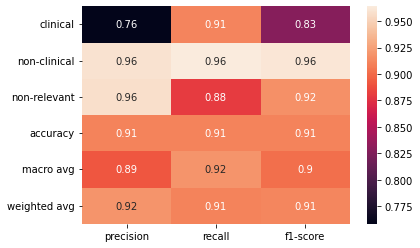

In [25]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

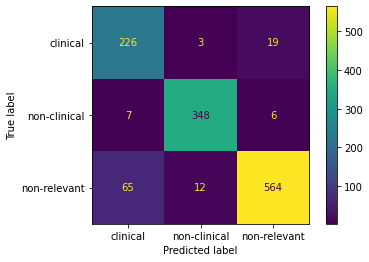

In [26]:

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [27]:
#Save the model to path
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_biobert/special_tokens_map.json


# BioBert Epoch 5

In [ ]:
#with 5
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=5)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 5
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.596500,0.847039,0.870737,0.869600,0.856186
2,0.185000,0.628525,0.853758,0.887438,0.872800,0.862776
3,0.106100,0.664421,0.857006,0.878408,0.880000,0.866062
4,0.106100,0.810715,0.847468,0.876726,0.863200,0.852759
5,0.040300,0.776101,0.863454,0.879880,0.884800,0.870719


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=1825, training_loss=0.09437965105657709, metrics={'train_runtime': 1687.7063, 'train_samples_per_second': 8.636, 'train_steps_per_second': 1.081, 'total_flos': 3821464418015412.0, 'train_loss': 0.09437965105657709, 'epoch': 5.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)

labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.72      0.80      0.76       248
non-clinical       0.95      0.97      0.96       361
non-relevant       0.92      0.87      0.89       641

    accuracy                           0.88      1250
   macro avg       0.86      0.88      0.87      1250
weighted avg       0.89      0.88      0.89      1250

Confusion Matrix: [[198   5  45]
 [  6 351   4]
 [ 71  13 557]]


<AxesSubplot:>

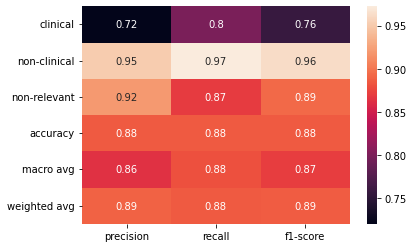

In [ ]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

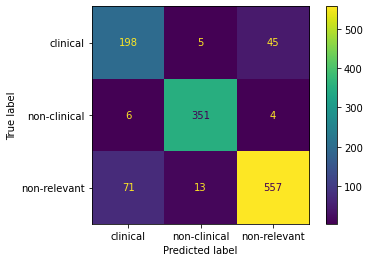

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_biobert/special_tokens_map.json


# BioBert Epoch = 2

In [ ]:
#with 2
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=2)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 2
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.949734,0.837648,0.864631,0.860800,0.848520
2,0.065200,0.839151,0.863948,0.885310,0.885600,0.873224


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=730, training_loss=0.05020572649289484, metrics={'train_runtime': 674.1435, 'train_samples_per_second': 8.648, 'train_steps_per_second': 1.083, 'total_flos': 1529295865097994.0, 'train_loss': 0.05020572649289484, 'epoch': 2.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)

labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.73      0.81      0.77       248
non-clinical       0.94      0.98      0.96       361
non-relevant       0.93      0.86      0.89       641

    accuracy                           0.89      1250
   macro avg       0.86      0.89      0.87      1250
weighted avg       0.89      0.89      0.89      1250

Confusion Matrix: [[202   4  42]
 [  4 355   2]
 [ 71  20 550]]


<AxesSubplot:>

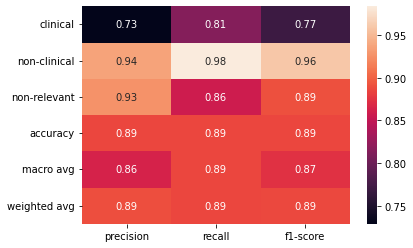

In [ ]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

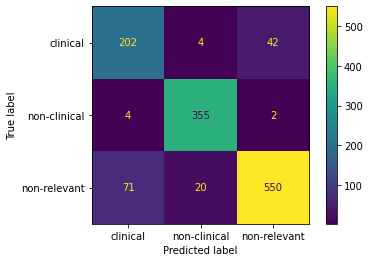

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_biobert/special_tokens_map.json


# emilyalsentzer/Bio_ClinicalBERT

In [ ]:

# Same as before
#checkpoint = "bert-base-uncased"
checkpoint = "emilyalsentzer/Bio_ClinicalBERT"

#model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(checkpoint, model_max_length=512)

#esta parte de aqui no termina utilizandose solamnete el tokenizer

Could not locate the tokenizer configuration file, will try to use the model config instead.


loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--emilyalsentzer--Bio_ClinicalBERT/snapshots/41943bf7f983007123c758373c5246305cc536ec/config.json
Model config BertConfig {
  "_name_or_path": "emilyalsentzer/Bio_ClinicalBERT",
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.26.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 28996
}



loading file vocab.txt from cache at /root/.cache/huggingface/hub/models--emilyalsentzer--Bio_ClinicalBERT/snapshots/41943bf7f983007123c758373c5246305cc536ec/vocab.txt
loading file tokenizer.json from cache at None
loading file added_tokens.json from cache at None
loading file special_tokens_map.json from cache at None
loading file tokenizer_config.json from cache at None
loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--emilyalsentzer--Bio_ClinicalBERT/snapshots/41943bf7f983007123c758373c5246305cc536ec/config.json
Model config BertConfig {
  "_name_or_path": "emilyalsentzer/Bio_ClinicalBERT",
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id

In [ ]:
#revisar esta parte
from transformers import AutoConfig, AutoModelForSequenceClassification
# define the mappings as dictionaries
label2id = {'clinical':0, 'non-clinical':1, 'non-relevant': 2}
id2label = {0:'clinical', 1:'non-clinical', 2:'non-relevant'}
# define config
config = AutoConfig.from_pretrained(checkpoint, label2id=label2id, id2label=id2label, model_max_length=512)
# load model with config
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=config)
# export model
#model.save_pretrained(target_name_or_path)

loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--emilyalsentzer--Bio_ClinicalBERT/snapshots/41943bf7f983007123c758373c5246305cc536ec/config.json
Model config BertConfig {
  "_name_or_path": "emilyalsentzer/Bio_ClinicalBERT",
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "clinical",
    "1": "non-clinical",
    "2": "non-relevant"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "label2id": {
    "clinical": 0,
    "non-clinical": 1,
    "non-relevant": 2
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.26.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 28996
}



loading weights file pytorch_model.bin from cache at /root/.cache/huggingface/hub/models--emilyalsentzer--Bio_ClinicalBERT/snapshots/41943bf7f983007123c758373c5246305cc536ec/pytorch_model.bin
Some weights of the model checkpoint at emilyalsentzer/Bio_ClinicalBERT were not used when initializing BertForSequenceClassification: ['cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForSequenceClassification from the checkpoint of a model that you expect to be exac

In [ ]:
def tokenize_function(example):
    return tokenizer(example["text"], truncation=True) #cuidado agregue padding para usar la segunda opcion

In [ ]:
tokenized_datasets = raw_dataset.map(tokenize_function, batched=True)
tokenized_datasets

Map:   0%|          | 0/2915 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1250
    })
})

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Epocs 3

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch")
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 3
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.479117,0.841044,0.878162,0.840000,0.836909
2,0.375400,0.392404,0.875739,0.894057,0.895200,0.883747
3,0.194600,0.395177,0.872926,0.902064,0.893600,0.884155


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=1095, training_loss=0.27398441610815316, metrics={'train_runtime': 959.5238, 'train_samples_per_second': 9.114, 'train_steps_per_second': 1.141, 'total_flos': 2291261531077008.0, 'train_loss': 0.27398441610815316, 'epoch': 3.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.72      0.88      0.79       248
non-clinical       0.95      0.98      0.96       361
non-relevant       0.95      0.85      0.90       641

    accuracy                           0.89      1250
   macro avg       0.87      0.90      0.88      1250
weighted avg       0.90      0.89      0.90      1250

Confusion Matrix: [[217   5  26]
 [  3 353   5]
 [ 81  13 547]]


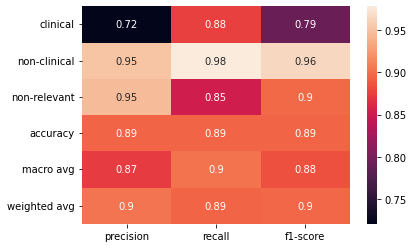

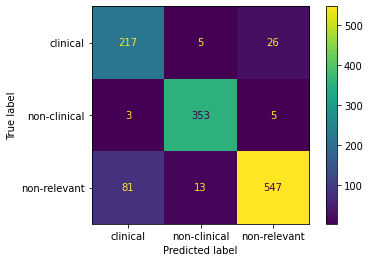

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio_cli_bert/special_tokens_map.json


# Epoc 5

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=5)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 5
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.508868,0.862703,0.877648,0.883200,0.869383
2,0.199400,0.534913,0.865402,0.886987,0.881600,0.871953
3,0.118200,0.582934,0.877481,0.884472,0.894400,0.880849
4,0.118200,0.734906,0.866510,0.898664,0.886400,0.877542
5,0.054700,0.817885,0.865150,0.889564,0.886400,0.875151


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=1825, training_loss=0.10492685500889608, metrics={'train_runtime': 1596.9432, 'train_samples_per_second': 9.127, 'train_steps_per_second': 1.143, 'total_flos': 3816620458883568.0, 'train_loss': 0.10492685500889608, 'epoch': 5.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.72      0.84      0.77       248
non-clinical       0.95      0.98      0.96       361
non-relevant       0.93      0.85      0.89       641

    accuracy                           0.89      1250
   macro avg       0.87      0.89      0.88      1250
weighted avg       0.89      0.89      0.89      1250

Confusion Matrix: [[208   6  34]
 [  3 352   6]
 [ 79  14 548]]


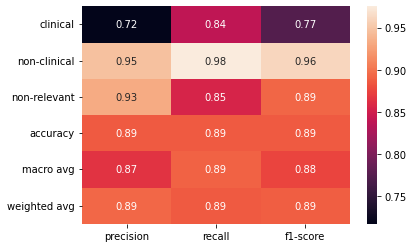

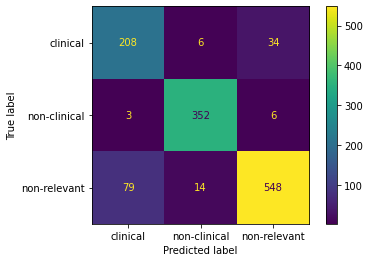

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio_cli_bert/special_tokens_map.json


# Epoc 2

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=2)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 2
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.927644,0.849983,0.893168,0.864000,0.858624
2,0.052100,0.940311,0.867976,0.895864,0.890400,0.879256


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=730, training_loss=0.041629202725136115, metrics={'train_runtime': 637.439, 'train_samples_per_second': 9.146, 'train_steps_per_second': 1.145, 'total_flos': 1527768060037632.0, 'train_loss': 0.041629202725136115, 'epoch': 2.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.73      0.85      0.79       248
non-clinical       0.93      0.98      0.95       361
non-relevant       0.95      0.85      0.90       641

    accuracy                           0.89      1250
   macro avg       0.87      0.90      0.88      1250
weighted avg       0.90      0.89      0.89      1250

Confusion Matrix: [[212  10  26]
 [  3 353   5]
 [ 76  17 548]]


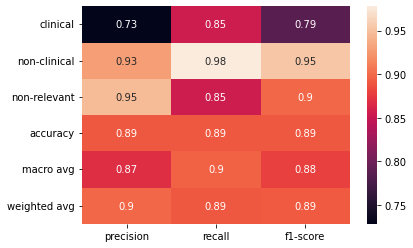

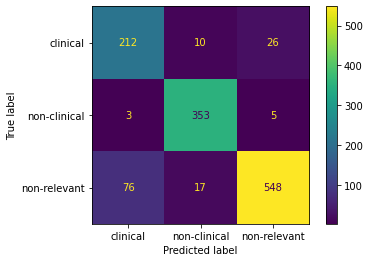

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio_cli_bert/special_tokens_map.json


 
# nlpie/bio-distilbert-uncased 

In [ ]:
# Same as before
#checkpoint = "bert-base-uncased"
checkpoint = "nlpie/bio-distilbert-uncased"

#model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(checkpoint, model_max_length=512)

#esta parte de aqui no termina utilizandose solamnete el tokenizer

In [ ]:
#revisar esta parte
from transformers import AutoConfig, AutoModelForSequenceClassification
# define the mappings as dictionaries
label2id = {'clinical':0, 'non-clinical':1, 'non-relevant': 2}
id2label = {0:'clinical', 1:'non-clinical', 2:'non-relevant'}
# define config
config = AutoConfig.from_pretrained(checkpoint, label2id=label2id, id2label=id2label, model_max_length=512)
# load model with config
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=config)
# export model
#model.save_pretrained(target_name_or_path)

Some weights of the model checkpoint at nlpie/bio-distilbert-uncased were not used when initializing DistilBertForSequenceClassification: ['vocab_transform.weight', 'vocab_projector.weight', 'vocab_projector.bias', 'vocab_layer_norm.weight', 'vocab_layer_norm.bias', 'vocab_transform.bias']
- This IS expected if you are initializing DistilBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DistilBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at nlpie/bio-distilbert-uncased and are newly initialized: ['classifier.weight', 'classifier.bias', 'pre_

In [ ]:
def tokenize_function(example):
    return tokenizer(example["text"], truncation=True) #cuidado agregue padding para usar la segunda opcion

In [ ]:
tokenized_datasets = raw_dataset.map(tokenize_function, batched=True)
tokenized_datasets

Map:   0%|          | 0/2915 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 1250
    })
})

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# epochs 3

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch")
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

The following columns in the training set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 3
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 1095
  Number of trainable parameters = 66955779
You're using a DistilBertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster tha

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.362432,0.855189,0.898579,0.867200,0.862614
2,0.305700,0.317937,0.874317,0.900872,0.893600,0.883948
3,0.151600,0.378268,0.875529,0.892006,0.895200,0.882654


The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8


Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-1000
Configuration saved in debbie-trainer/checkpoint-1000/config.json
Model weights saved in debbie-trainer/checkpoint-1000/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-1000/tokenizer_config.json
Special tokens file s

TrainOutput(global_step=1095, training_loss=0.22014070101524597, metrics={'train_runtime': 484.475, 'train_samples_per_second': 18.05, 'train_steps_per_second': 2.26, 'total_flos': 1146830048145072.0, 'train_loss': 0.22014070101524597, 'epoch': 3.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.73      0.83      0.78       248
non-clinical       0.96      0.97      0.97       361
non-relevant       0.93      0.88      0.90       641

    accuracy                           0.90      1250
   macro avg       0.88      0.89      0.88      1250
weighted avg       0.90      0.90      0.90      1250

Confusion Matrix: [[205   6  37]
 [  4 350   7]
 [ 70   7 564]]


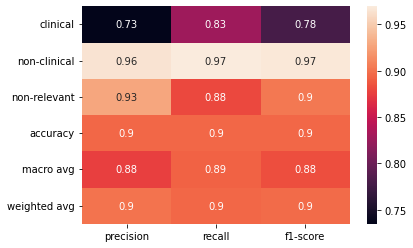

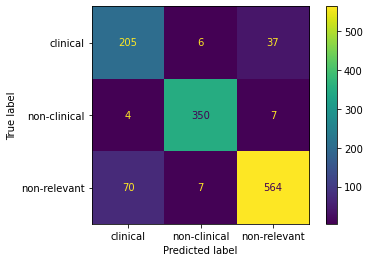

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_3_bio-distilbert-uncased_bert/special_tokens_map.json


# epochs 5

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=5)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 5
  Instantaneous batch size per device = 8
  Total train batc

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.477664,0.868811,0.903544,0.885600,0.879216
2,0.125000,0.576238,0.873206,0.892836,0.892000,0.880967
3,0.055300,0.642790,0.863878,0.892779,0.885600,0.874740
4,0.055300,0.702597,0.872170,0.899733,0.891200,0.882160
5,0.021800,0.704870,0.871893,0.900218,0.892000,0.882644


The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****


TrainOutput(global_step=1825, training_loss=0.0568698591728733, metrics={'train_runtime': 798.7412, 'train_samples_per_second': 18.247, 'train_steps_per_second': 2.285, 'total_flos': 1909559884521024.0, 'train_loss': 0.0568698591728733, 'epoch': 5.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.72      0.88      0.79       248
non-clinical       0.96      0.97      0.96       361
non-relevant       0.94      0.85      0.90       641

    accuracy                           0.89      1250
   macro avg       0.87      0.90      0.88      1250
weighted avg       0.90      0.89      0.89      1250

Confusion Matrix: [[217   4  27]
 [  4 351   6]
 [ 82  12 547]]


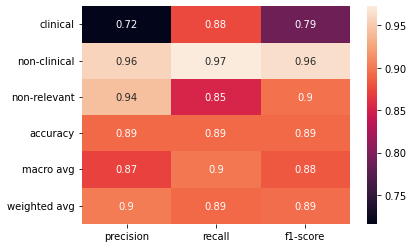

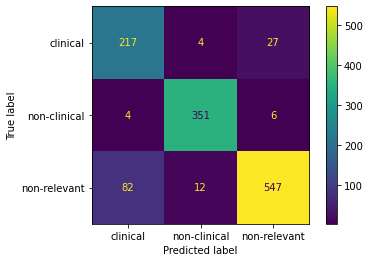

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_5_bio-distilbert-uncased_bert/special_tokens_map.json


# epochs 2

In [ ]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=2)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 2
  Instantaneous batch size per device = 8
  Total train batc

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,1.092506,0.847226,0.889153,0.861600,0.855382
2,0.028100,0.922830,0.862816,0.898717,0.884000,0.875224


The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****


TrainOutput(global_step=730, training_loss=0.020701046839152297, metrics={'train_runtime': 318.72, 'train_samples_per_second': 18.292, 'train_steps_per_second': 2.29, 'total_flos': 764928006472944.0, 'train_loss': 0.020701046839152297, 'epoch': 2.0})

In [ ]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]
predictions = np.argmax(logits, axis=-1)

The following columns in the test set don't have a corresponding argument in `DistilBertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `DistilBertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.70      0.89      0.78       248
non-clinical       0.94      0.98      0.96       361
non-relevant       0.96      0.83      0.89       641

    accuracy                           0.88      1250
   macro avg       0.86      0.90      0.88      1250
weighted avg       0.90      0.88      0.89      1250

Confusion Matrix: [[221   5  22]
 [  6 352   3]
 [ 90  19 532]]


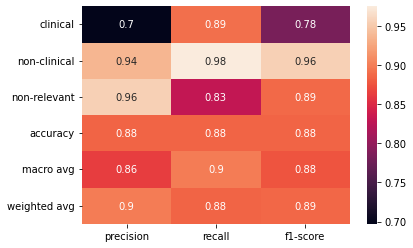

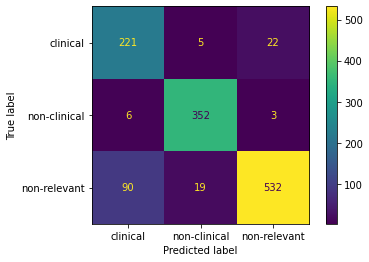

In [ ]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [ ]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0_epoch_2_bio-distilbert-uncased_bert/special_tokens_map.json
